# Best length exponent e across both control recordings

Same test as `EOD_length_scaling_oracle_g_3fish.ipynb`, now on both controls, where only one fish emits:

| recording | emitter | silent fish |
|---|---|---|
| 3-fish (2024-10-15) | fish 0, the **smallest** | fish 1, fish 2 (larger) |
| 2-fish (2024-02-13) | fish 1, the **larger** | fish 0 (smaller) |

In the 3-fish recording a larger e only makes the silent fish's predictions larger, so accuracy rises with e; in the 2-fish
recording it makes the silent fish's prediction smaller, so beyond some e it can win where the emitter fits poorly. The e that
does best on both together is the best estimate these controls allow.

My model, BEM conductivities (interior 100 × water, skin 0.05 × water over 0.005 cm), sink at the tail tip, sign fixed:
$m_f = -u_f$ from each recording's cached unit-current voltages; $r$ the recorded peak pattern (volts).
- **Known gain** per recording: $g$ = median over the better-list EODs of the emitter's least-squares gain
  $r\cdot m_{em}/\lVert m_{em}\rVert^2$; one $g$ for all EODs of that recording.
- **Length**: prediction of fish $f$ is $g\,\rho_f\,m_f$ with $\rho_f = (L_f/L_{em})^e$ ($\rho_{em} = 1$: the emitter's length is
  in $g$ once). Fixed lengths with the `fish_lengths.py` rules (`fish_lengths.zeus_lengths`) on each recording's ZEUS masks.
- **Rules**: A. voltage difference $d_f = \lVert r - g\rho_f m_f\rVert$; B. shape + log amplitude
  $d_f^2 = \lVert\hat r-\hat m_f\rVert^2/\tau^2 + (\log a_f - \log(g\rho_f))^2/\sigma^2$ ($a_f$ fish $f$'s own least-squares gain,
  $a_f \le 0$ rules it out; $\sigma$, $\tau^2$ from the emitter on the better list of that recording).
- **Best e**: the e that maximises the mean of the two recordings' % correct (each recording weighted equally), on a grid of
  0.1 from −1 to 10 (e < 0, smaller fish emitting more, only as a check). 95% interval of the best e: 1,000 bootstrap resamples
  of the EODs within each recording.

EOD sets: all EODs and the better list of good frames of each recording (`good_frames_better_list.csv`: common good frames with
every fish's mask ≥ 0.8 × its median length).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fish_lengths import zeus_lengths
%matplotlib inline

REC = {
    '3-fish': dict(res='results/eod_ground_truth_3fish', cache='model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl', fish=(0, 1, 2),
                   emitter=0, track='data/3_fish_silent/elephantnose_20241015T141225_tracking_final.pkl', lengths='fish_lengths_3fish.json'),
    '2-fish': dict(res='results/eod_ground_truth', cache='model_voltages_N150_sinks0and0.05_el46ee63_bem_a453a8.pkl', fish=(0, 1),
                   emitter=1, track='data/2_fish_silent/elephantnose_20240213T143321_tracking_final.pkl', lengths='fish_lengths_2fish.json'),
}
OUT = 'results/length_scaling_both_recordings'
import os; os.makedirs(OUT, exist_ok=True)
E_GRID = np.round(np.arange(-1, 10.001, 0.1), 2)
RULES = ['A. voltage difference', 'B. shape + log amplitude']
N_BOOT = 1000

## Fixed body lengths

The 3-fish lengths were measured in `EOD_length_scaling_3fish.ipynb` with the same rules (`zeus_lengths` reproduces them exactly);
the 2-fish ones are measured here.

In [2]:
for name, c in REC.items():
    path = f"{c['res']}/{c['lengths']}"
    if not os.path.exists(path):
        json.dump(dict(recording=name, units='L_tank = L_px / (P - 1)', method='fish_lengths.zeus_lengths', fish=zeus_lengths(c['track'], c['fish'])),
                  open(path, 'w'), indent=1)
    lens = json.load(open(path))['fish']
    c['L'] = np.array([lens[str(f)]['L_tank'] for f in c['fish']])
    c['len_table'] = pd.DataFrame({f: {k: lens[str(f)][k] for k in ('L_px', 'n_frames_used', 'L_px_range')} for f in c['fish']}).T
display(pd.concat({n: c['len_table'].assign(L_cm=lambda t: (t.L_px.astype(float) / (912 / 60)).round(2),
                                            ratio_to_emitter=c['L'] / c['L'][c['emitter']])
                   for n, c in REC.items()}).rename_axis(['recording', 'fish']))

L_px n_frames_used        L_px_range   L_cm  \
recording fish                                                   
3-fish    0     180.786            27  [160.22, 185.55]  11.89   
          1     251.485             5  [242.48, 256.65]  16.55   
          2      213.44             2  [209.42, 217.46]  14.04   
2-fish    0      168.38            30  [159.48, 178.42]  11.08   
          1      250.64             5   [240.56, 253.7]  16.49   

                ratio_to_emitter  
recording fish                    
3-fish    0             1.000000  
          1             1.391065  
          2             1.180622  
2-fish    0             0.671801  
          1             1.000000

## Gain, σ, τ and the picks for every e

In [3]:
def unit_max(x): return x / np.abs(x).max(axis=-1, keepdims=True)

params = {}
for name, c in REC.items():
    A = pd.read_csv(f"{c['res']}/conductivities/eod_assignments.csv", index_col='row')
    cache = pd.read_pickle(f"{c['res']}/conductivities/{c['cache']}")
    assert (cache.frame.to_numpy() == A.Frame.to_numpy()).all()
    R = np.stack(cache.v_rec.map(np.asarray))
    M = -np.stack(cache.u_sink0.map(lambda u: np.asarray(u, float)))
    ok = np.isfinite(M).all(axis=2)
    better = A.Frame.isin(pd.read_csv(f"{c['res']}/good_frames_better_list.csv").frame).to_numpy()
    em = c['emitter']
    a = (R[:, None] * M).sum(2) / (M * M).sum(2)                           # each fish's own least-squares gain
    cal = better & ok[:, em]; g_i = a[cal, em]
    g = np.median(g_i); sigma = np.std(np.log(g_i[g_i > 0]))
    shape2 = np.linalg.norm(unit_max(R)[:, None] - unit_max(M), axis=2) ** 2
    tau2 = np.median(shape2[cal, em])
    with np.errstate(invalid='ignore', divide='ignore'):
        loga = np.where(a > 0, np.log(a), np.nan)
    correct = {r: np.zeros((len(A), len(E_GRID)), bool) for r in RULES}
    for j, e in enumerate(E_GRID):
        rho = (c['L'] / c['L'][em]) ** e
        dA = np.linalg.norm(R[:, None] - g * rho[None, :, None] * M, axis=2)
        dB = shape2 / tau2 + (loga - np.log(g * rho)[None]) ** 2 / sigma ** 2
        for r, d in zip(RULES, (dA, dB)):
            d = np.where(ok & np.isfinite(d), d, np.inf)
            correct[r][:, j] = np.isfinite(d.min(1)) & (d.argmin(1) == em)
    c.update(n=len(A), better=better, correct=correct)
    params[name] = {'g (volts per model unit)': g, 'g IQR low': np.percentile(g_i, 25), 'g IQR high': np.percentile(g_i, 75),
                    'sigma': sigma, 'tau^2': tau2, 'n better-list EODs': cal.sum()}
params = pd.DataFrame(params); params.to_csv(f'{OUT}/oracle_g_params.csv')
display(params.round(4))

,3-fish,2-fish
g (volts per model unit),0.9152,0.4925
g IQR low,0.7821,0.3670
g IQR high,1.0713,0.6188
sigma,0.3561,0.5036
tau^2,0.3131,0.1391
n better-list EODs,6751.0000,3501.0000


## % correct against e, and the best e

In [4]:
SETS = ['all EODs', 'better list of good frames']
def mask(c, s): return np.ones(c['n'], bool) if s == 'all EODs' else c['better']

rows = []
for r in RULES:
    for s in SETS:
        acc = {n: 100 * c['correct'][r][mask(c, s)].mean(0) for n, c in REC.items()}
        for j, e in enumerate(E_GRID):
            rows.append({'rule': r, 'EODs': s, 'e': e, **{f'% correct, {n}': acc[n][j] for n in REC},
                         '% correct, mean of both': np.mean([acc[n][j] for n in REC])})
T = pd.DataFrame(rows)
T.to_csv(f'{OUT}/accuracy_vs_e_both.csv', index=False)

rng = np.random.default_rng(0)
best = []
for r in RULES:
    for s in SETS:
        t = T[(T.rule == r) & (T.EODs == s)].reset_index(drop=True)
        boot = np.zeros((N_BOOT, len(E_GRID)))
        for n, c in REC.items():                                           # resample EODs within each recording
            C = c['correct'][r][mask(c, s)].astype(float); k = len(C)
            w = rng.multinomial(k, np.full(k, 1 / k), size=N_BOOT)
            boot += 100 * (w @ C) / k / len(REC)
        e_boot = E_GRID[boot.argmax(1)]
        j = t['% correct, mean of both'].idxmax()
        best.append({'rule': r, 'EODs': s, 'best e': t.e[j], 'best e, 95% bootstrap interval': f'{np.percentile(e_boot, 2.5):.1f}–{np.percentile(e_boot, 97.5):.1f}',
                     '% correct mean at best e': t['% correct, mean of both'][j],
                     **{f'% correct {n} at best e': t[f'% correct, {n}'][j] for n in REC},
                     **{f'best e for {n} alone': t.e[t[f'% correct, {n}'].idxmax()] for n in REC},
                     **{f'% correct {n} at e = 0': t[f'% correct, {n}'][t.e == 0].item() for n in REC}})
best = pd.DataFrame(best); best.to_csv(f'{OUT}/best_e_both.csv', index=False)
display(best.round(2).T)
show = [0, 0.5, 1, 1.5, 2, 3, 4, 6, 8, 10]
display(T[T.e.isin(show)].pivot_table(index='e', columns=['rule', 'EODs'], values=['% correct, 3-fish', '% correct, 2-fish', '% correct, mean of both']).round(2))

,0,1,2,3
rule,A. voltage difference,A. voltage difference,B. shape + log amplitude,B. shape + log amplitude
EODs,all EODs,better list of good frames,all EODs,better list of good frames
best e,10.0,-0.3,10.0,9.9
"best e, 95% bootstrap interval",10.0–10.0,-0.8–0.3,10.0–10.0,9.3–9.9
% correct mean at best e,93.88,97.48,92.18,98.05
% correct 3-fish at best e,99.37,96.99,90.32,99.04
% correct 2-fish at best e,88.39,97.97,94.04,97.06
best e for 3-fish alone,10.0,8.5,10.0,9.9
best e for 2-fish alone,-1.0,-1.0,10.0,9.6
% correct 3-fish at e = 0,88.56,97.36,85.97,96.33


% correct, 2-fish                             \
rule  A. voltage difference                              
EODs               all EODs better list of good frames   
e                                                        
-0.0                  93.04                      97.49   
 0.5                  92.17                      96.83   
 1.0                  91.25                      95.80   
 1.5                  90.58                      94.66   
 2.0                  90.01                      93.86   
 3.0                  89.28                      93.09   
 4.0                  88.95                      92.72   
 6.0                  88.48                      92.57   
 8.0                  88.36                      92.37   
 10.0                 88.39                      92.40   

                                                           \
rule  B. shape + log amplitude                              
EODs                  all EODs better list of good frames   
e                                                           
-0.0                     92.43                      96.57   
 0.5                     92.50                      96.57   
 1.0                     92.48                      96.60   
 1.5                     92.50                      96.52   
 2.0                     92.58                      96.49   
 3.0                     92.76                      96.40   
 4.0                     93.00                      96.46   
 6.0                     93.44                      96.72   
 8.0                     93.75                      96.92   
 10.0                    94.04                      97.06   

          % correct, 3-fish                             \
rule  A. voltage difference                              
EODs               all EODs better list of good frames   
e                                                        
-0.0                  88.56                      97.36   
 0.5                  89.62                      97.75   
 1.0                  90.54                      97.88   
 1.5                  91.54                      98.16   
 2.0                  92.50                      98.53   
 3.0                  94.54                      99.21   
 4.0                  95.88                      99.53   
 6.0                  97.69                      99.81   
 8.0                  98.75                      99.94   
 10.0                 99.37                      99.99   

                                                           \
rule  B. shape + log amplitude                              
EODs                  all EODs better list of good frames   
e                                                           
-0.0                     85.97                      96.33   
 0.5                     86.29                      96.64   
 1.0                     86.60                      96.83   
 1.5                     86.72                      96.92   
 2.0                     87.02                      97.13   
 3.0                     87.63                      97.64   
 4.0                     88.29                      98.15   
 6.0                     89.41                      98.68   
 8.0                     89.94                      98.90   
 10.0                    90.32                      99.04   

      % correct, mean of both                             \
rule    A. voltage difference                              
EODs                 all EODs better list of good frames   
e                                                          
-0.0                    90.80                      97.42   
 0.5                    90.90                      97.29   
 1.0                    90.89                      96.84   
 1.5                    91.06                      96.41   
 2.0                    91.26                      96.20   
 3.0                    91.91                      96.15   
 4.0                    92.41                      96.12   
 6.0          

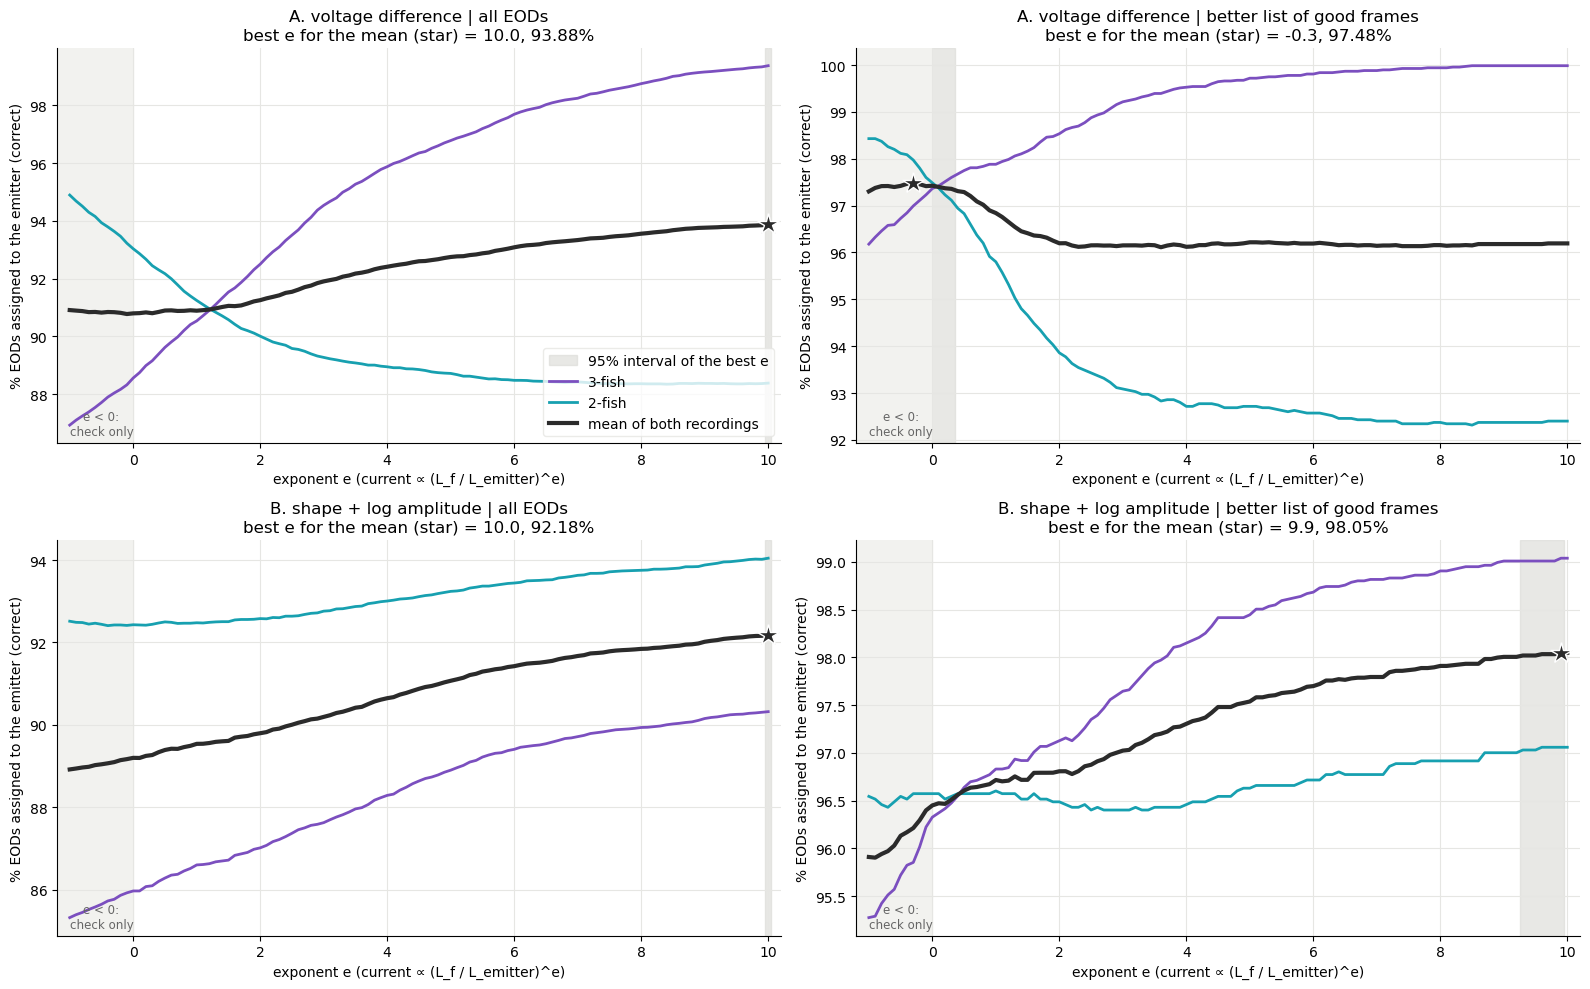

In [5]:
COL = {'3-fish': '#7B4FBF', '2-fish': '#17A0B0', 'mean of both': '#2b2b2b'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3'})
fig, axs = plt.subplots(2, 2, figsize=(16, 10))
for i, r in enumerate(RULES):
    for k, s in enumerate(SETS):
        ax = axs[i, k]; t = T[(T.rule == r) & (T.EODs == s)]
        b = best[(best.rule == r) & (best.EODs == s)].iloc[0]
        lo, hi = map(float, b['best e, 95% bootstrap interval'].split('–'))
        ax.axvspan(lo - 0.05, hi + 0.05, color='#d9d9d4', alpha=0.6, zorder=0, label='95% interval of the best e')
        ax.axvspan(E_GRID[0] - 0.2, 0, color='#f2f2ef', zorder=0)
        for n in ('3-fish', '2-fish', 'mean of both'):
            ax.plot(t.e, t[f'% correct, {n}'], color=COL[n], lw=3 if n == 'mean of both' else 2, label=n if n != 'mean of both' else 'mean of both recordings')
        ax.plot(b['best e'], b['% correct mean at best e'], '*', color=COL['mean of both'], ms=16, mec='w', zorder=5)
        ax.set(title=f"{r} | {s}\nbest e for the mean (star) = {b['best e']:.1f}, {b['% correct mean at best e']:.2f}%", xlabel='exponent e (current ∝ (L_f / L_emitter)^e)', ylabel='% EODs assigned to the emitter (correct)',
               xlim=(E_GRID[0] - 0.2, E_GRID[-1] + 0.2))
        ax.text(-0.5, 0.02, 'e < 0:\ncheck only', transform=ax.get_xaxis_transform(), ha='center', fontsize=8.5, color='0.4')
axs[0, 0].legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#e6e6e3')
plt.tight_layout(); fig.savefig(f'{OUT}/accuracy_vs_e_both.png', dpi=120); plt.show()